# MCMC analysis of cosmological FRB constraints using the Pade Approximants

**Note**: This notebook uses the updated formalism developed for Zhuge+ (2025) [[here](https://arxiv.org/abs/2508.05161)], and a Gaussian PDF for comparison.

**Default Runs**

- $N_s=15000$ samples (minus `burn-in`)
- `z_min=0.25`
- Cosmological priors: $H_0 \ \epsilon \ [40, 100]$ km/s/Mpc, $\Omega_m \ \epsilon \ [0.0, 1.0]$, $w \ \epsilon \ [-2.0, 0.0]$

## Run properties and loading modules

In [1]:
### If the MCMC functions need to be imported from a file, this should be OFF
## Depends on how the OS handles multiprossecing
SAVE_DATA = True
SAVE_FIG = False

In [2]:
import sys
sys.path.append('../Python_scripts')
DATA_PATH = './interpolation/095_C0mean.npz'

### Import packages
from config import *
from support import *
from cosmo_support import *
from mcmc_support import *

In [3]:
## Plotting
plt.rcParams['font.family'] ='Times New Roman'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

## Collect Data

In [4]:
import pandas as pd

In [5]:
frb_data_all=pd.read_csv('../Data/FRB_new_highz_event.csv')

In [6]:
z_cut=0.25

## Cutting the data
frb_data_cut = frb_data_all[frb_data_all['FRB'] != 'FRB 20190520B'] 
frb_data_cut = frb_data_cut[frb_data_cut['FRB'] != 'FRB 20220831A']
frb_data_cut = frb_data_cut[frb_data_cut['z'] >= z_cut]

frb_data_cut_lowZ = frb_data_cut[frb_data_cut['FRB'] != 'FRB 20240304B']

print(f"Original data had {len(frb_data_all)}, while the cut data have {len(frb_data_cut)} FRBs.")
print(f"Original data had {len(frb_data_all)}, while the cut lowZ data have {len(frb_data_cut_lowZ)} FRBs.")

Original data had 118, while the cut data have 45 FRBs.
Original data had 118, while the cut lowZ data have 44 FRBs.


In [7]:
frb_data_cut.head()

,FRB,z,gl,gb,DM,"DM_MW, ISM(NE2001)","DM_MW, ISM(YMW16)",DM_ext(ne2001),DM_ext(ymw16),Ref.
3,FRB 20220610A,1.01500,8.839200,-70.185700,1458.10,30.96,13.58,1397.142120,1414.521089,ASKAP2
4,FRB 20220717A,0.36295,19.835158,-17.632032,637.34,118.33,83.22,489.008396,524.116215,https://arxiv.org/pdf/2407.02173
6,FRB 20230521B,1.35400,115.650000,9.970000,1342.90,133.40,197.80,1179.501944,1115.100378,https://arxiv.org/pdf/2409.16952
7,FRB 20230814A,0.55300,112.560000,13.200000,696.40,104.76,137.79,561.640318,528.611960,https://arxiv.org/pdf/2409.16952
8,FRB 20231220A,0.33550,143.290000,31.690000,491.20,50.27,45.17,410.934486,416.027064,https://arxiv.org/pdf/2409.16952


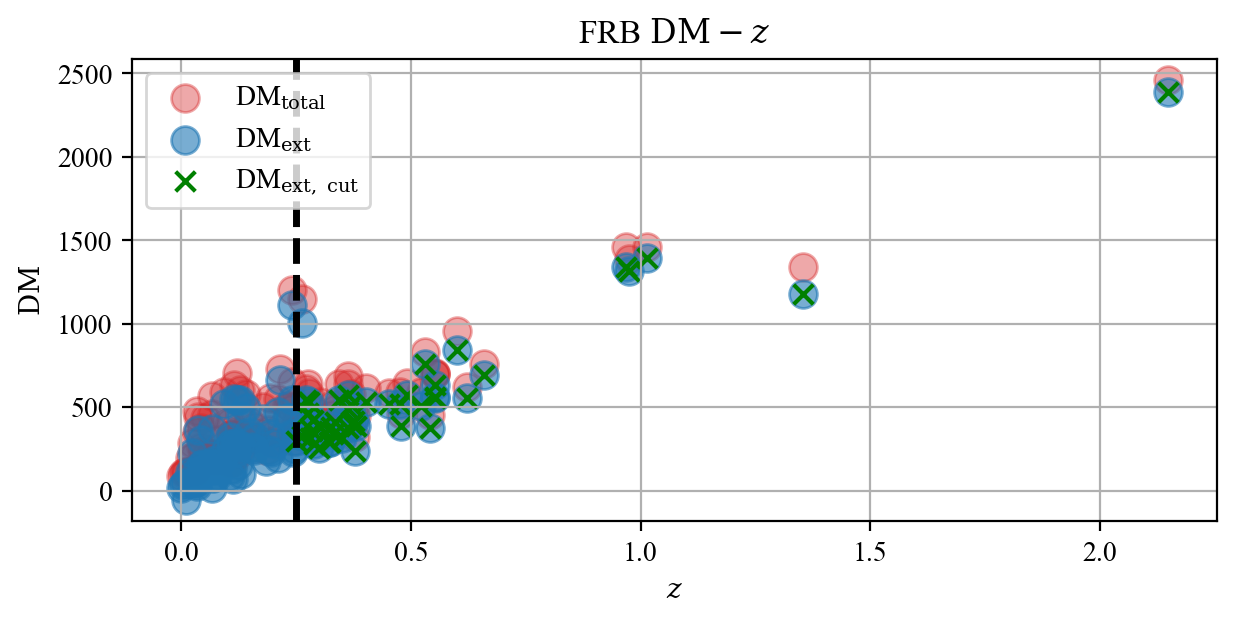

In [7]:
fig = plt.figure(figsize=(7, 3), dpi=200)
ax1 = fig.add_subplot(111)

ax1.scatter(frb_data_all['z'], frb_data_all['DM'], s=100, marker='o', label=r'DM$_{\rm total}$', alpha=0.4, c='tab:red')
ax1.scatter(frb_data_all['z'], frb_data_all['DM_ext(ne2001)'], s=100, marker='o', label=r'DM$_{\rm ext}$', alpha=0.6)
ax1.scatter(frb_data_cut['z'], frb_data_cut['DM_ext(ne2001)'], s=50, marker='x', label=r'DM$_{\rm ext,\ cut}$', c='green')

ax1.axvline(x=z_cut, ls='--', lw=2.5, c='black')
ax1.set_xlabel(r'$z$')
ax1.set_ylabel(r'${\rm DM}$')
ax1.set_title(r'FRB ${\rm DM}-z$')
ax1.grid(True)
ax1.legend(loc='upper left')


if SAVE_FIG:
    plt.savefig("figures/frb_all_cut_DM_z.png", dpi=200, bbox_inches='tight')

plt.show()
plt.close()

# Run MCMC analysis

**Note**:

- For *Gaussian* runs use: `run_mcmc_analysis`.
- For *PDF* runs use: `run_mcmc_analysis_pdf`, and provide the interpolation `data_path`.

**Pade (Approximate) ${\rm DM}$ calculation**

1. Gauss PDF

In [63]:
samples_PD_gauss, flat_samples_PD_gauss = run_mcmc_analysis(frb_data_cut['z'], frb_data_cut['DM_ext(ne2001)'], 200, log_probability_frb_Pade_gauss, N_samples=1500)

100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [01:16<00:00, 19.71it/s]


In [64]:
samples_PD_gauss_lowZ, flat_samples_PD_gauss_lowZ = run_mcmc_analysis(frb_data_cut_lowZ['z'], frb_data_cut_lowZ['DM_ext(ne2001)'], 200, log_probability_frb_Pade_gauss, N_samples=1500)

100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [01:25<00:00, 17.45it/s]


2. Zhuge+2025 PDF

In [65]:
samples_PD_pdf, flat_samples_PD_pdf = run_mcmc_analysis_pdf(frb_data_cut['z'], frb_data_cut['DM_ext(ne2001)'], 200, log_probability_frb_Pade_pdf, DATA_PATH, N_samples=2000)

C:\Users\klera\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [04:20<00:00,  7.67it/s]


In [66]:
samples_PD_pdf_lowZ, flat_samples_PD_pdf_lowZ = run_mcmc_analysis_pdf(frb_data_cut_lowZ['z'], frb_data_cut_lowZ['DM_ext(ne2001)'], 200, log_probability_frb_Pade_pdf, DATA_PATH, N_samples=2000)

100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [03:57<00:00,  8.42it/s]


3. Zhuge+2025 PDF + host

In [13]:
samples_PD_pdf_host, flat_samples_PD_pdf_host = run_mcmc_analysis_pdf_host(np.array(frb_data_cut['z']), np.array(frb_data_cut['DM_ext(ne2001)']), 50, log_probability_frb_Pade_pdf_host, DATA_PATH, N_samples=2000)

100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [05:16<00:00,  6.32it/s]


In [9]:
samples_PD_pdf_host_lowZ, flat_samples_PD_pdf_host_lowZ = run_mcmc_analysis_pdf_host(np.array(frb_data_cut_lowZ['z']), np.array(frb_data_cut_lowZ['DM_ext(ne2001)']), 50, log_probability_frb_Pade_pdf_host, DATA_PATH, N_samples=2000)

C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: divide by zero encountered in divide
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: divide by zero encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:281: RuntimeWarning: invalid value encountered in log
  np.exp(-(np.log(DM)-np.log(e_mu))**2/(2*(sigma_host**2)))
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\cosmo_support.py:280: RuntimeWarning: invalid value encountered in multiply
  pdf = 1.0/(sigma_host*np.sqrt(2*np.pi)*DM) * \
C:\Users\klera\Documents\GitHub\DM_cosmic_Pade\Notebooks\../Python_scripts\mcmc_support.py:190: RuntimeWarning: divide by zero encountered in log10
  log_prob = np.sum(np.log10(p_obs))
100

#### Save posterior data

In [20]:
if SAVE_DATA:
    np.save('./posterior/samples_PD_gauss.npy', flat_samples_PD_gauss)
    np.save('./posterior/samples_PD_gauss_lowZ.npy', flat_samples_PD_gauss_lowZ)

## Cosmological Constraints

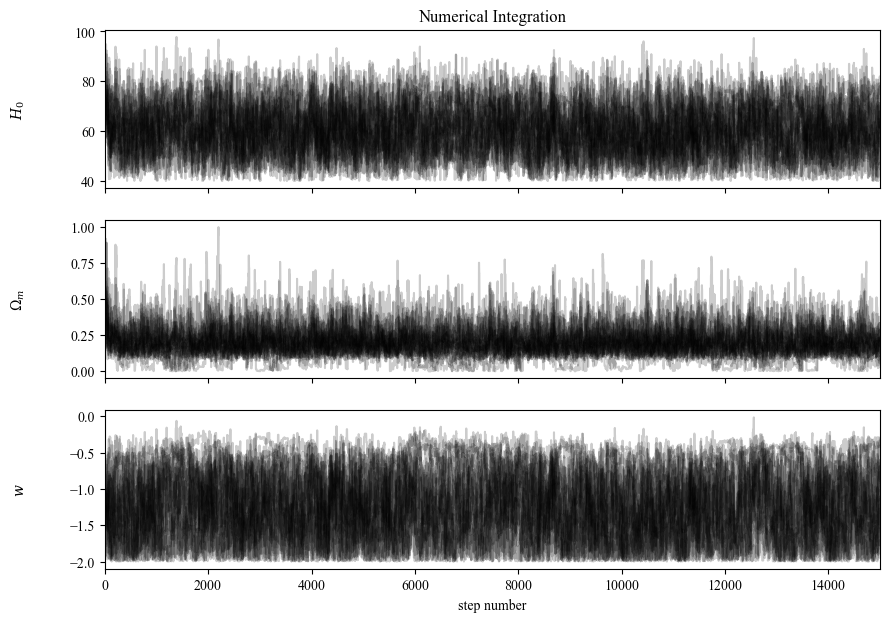

In [15]:
fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)

for idx, name in enumerate(labels):
    ax = axes[idx]
    ax.plot(samples_gauss[:, :, idx], "k", alpha=0.2)
    ax.set_xlim(0, len(samples_gauss))
    ax.set_ylabel(name)
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");
axes[0].set_title('Numerical Integration')

plt.show()

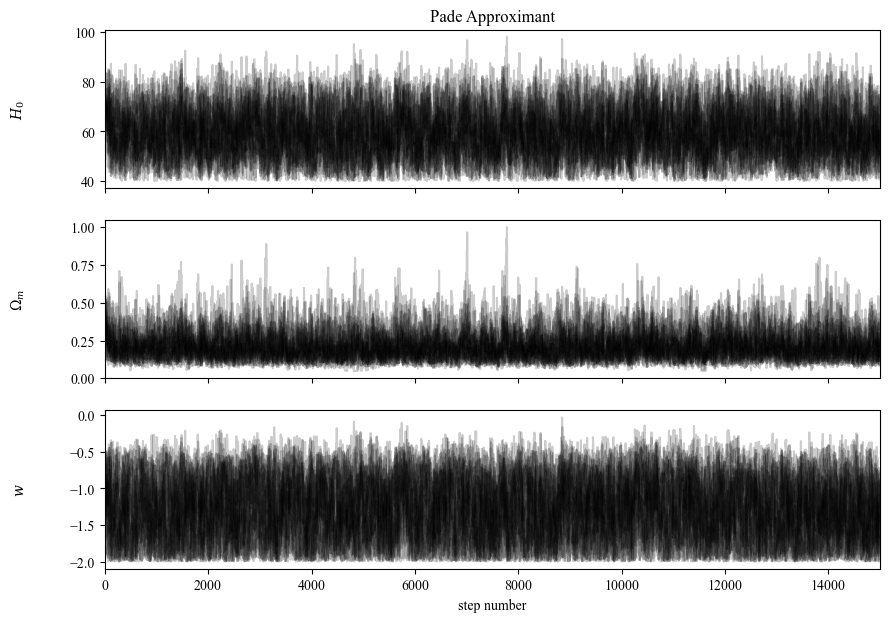

In [16]:
fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)
labels = [r"$H_0$", r"$\Omega_m$", r"$w$"]
for idx, name in enumerate(labels):
    ax = axes[idx]
    ax.plot(samples_PD_gauss[:, :, idx], "k", alpha=0.2)
    ax.set_xlim(0, len(samples_PD_gauss))
    ax.set_ylabel(name)
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");
axes[0].set_title('Pade Approximant')

plt.show()

**Garbadge events**

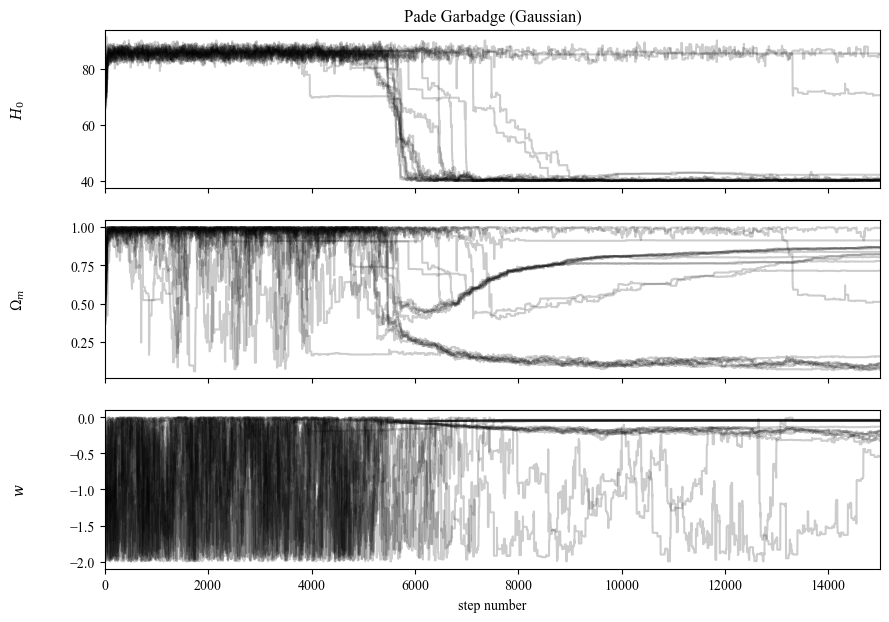

In [15]:
fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)
labels = [r"$H_0$", r"$\Omega_m$", r"$w$"]
for idx, name in enumerate(labels):
    ax = axes[idx]
    ax.plot(samples_PD_garbadge_gauss[:, :, idx], "k", alpha=0.2)
    ax.set_xlim(0, len(samples_PD_garbadge_gauss))
    ax.set_ylabel(name)
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");
axes[0].set_title('Pade Garbadge (Gaussian)')

plt.show()

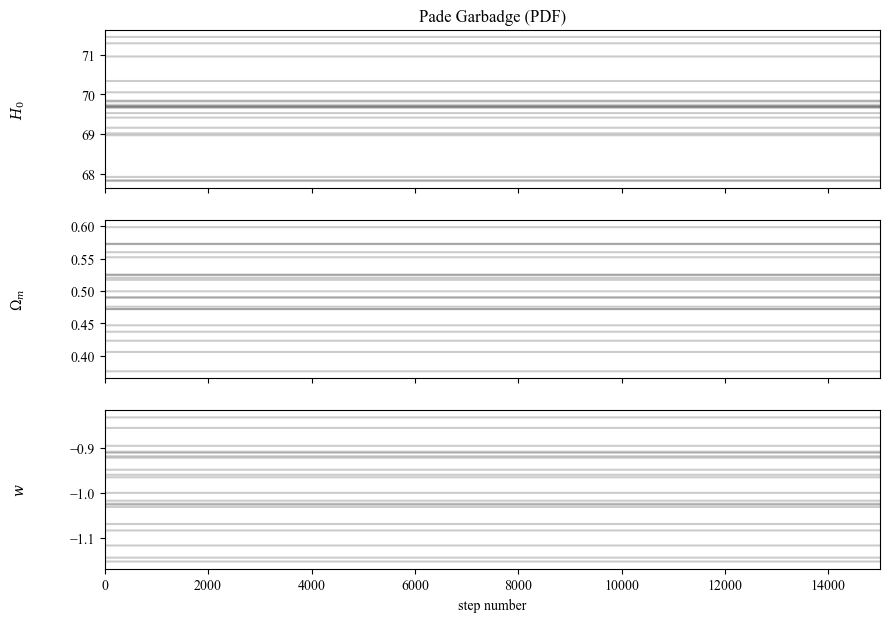

In [16]:
fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)
labels = [r"$H_0$", r"$\Omega_m$", r"$w$"]
for idx, name in enumerate(labels):
    ax = axes[idx]
    ax.plot(samples_PD_garbadge_pdf[:, :, idx], "k", alpha=0.2)
    ax.set_xlim(0, len(samples_PD_garbadge_pdf))
    ax.set_ylabel(name)
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");
axes[0].set_title('Pade Garbadge (PDF)')

plt.show()

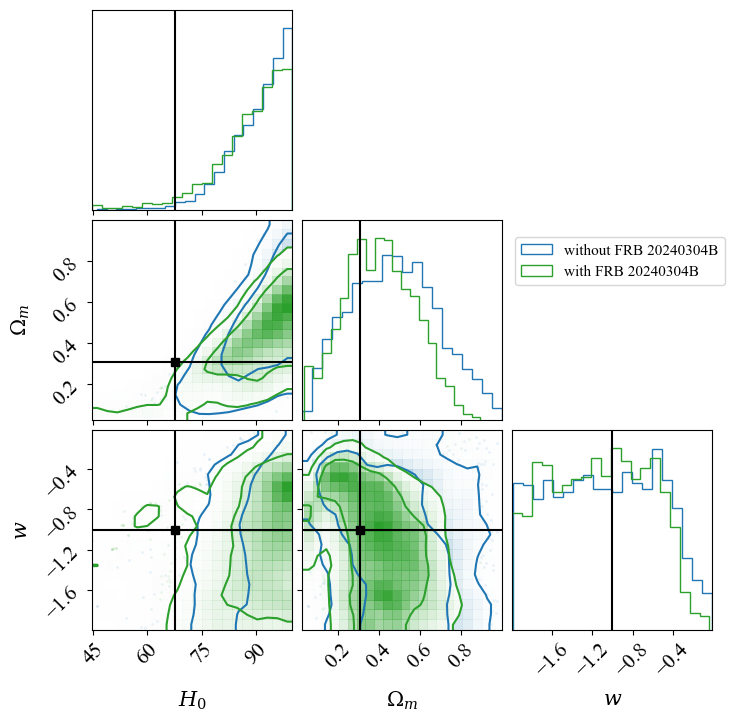

In [67]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$"]

fig = corner.corner(
    flat_samples_PD_gauss_lowZ, labels=labels, color="tab:blue",\
    smooth=True, label_kwargs={"fontsize": 15}, levels=(0.68, 0.95)
)
corner.corner(
    flat_samples_PD_gauss, fig=fig,\
    levels=(0.68, 0.95), color="tab:green", smooth=True,\
    truths=[HUBBLE, OMEGA_MATTER, W_LAMBDA], truth_color='black'
);

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=15)

plt.legend(['without FRB 20240304B', 'with FRB 20240304B'], loc='upper right', bbox_to_anchor=(0.1, 1., 1, 1), fontsize=11)
plt.show()

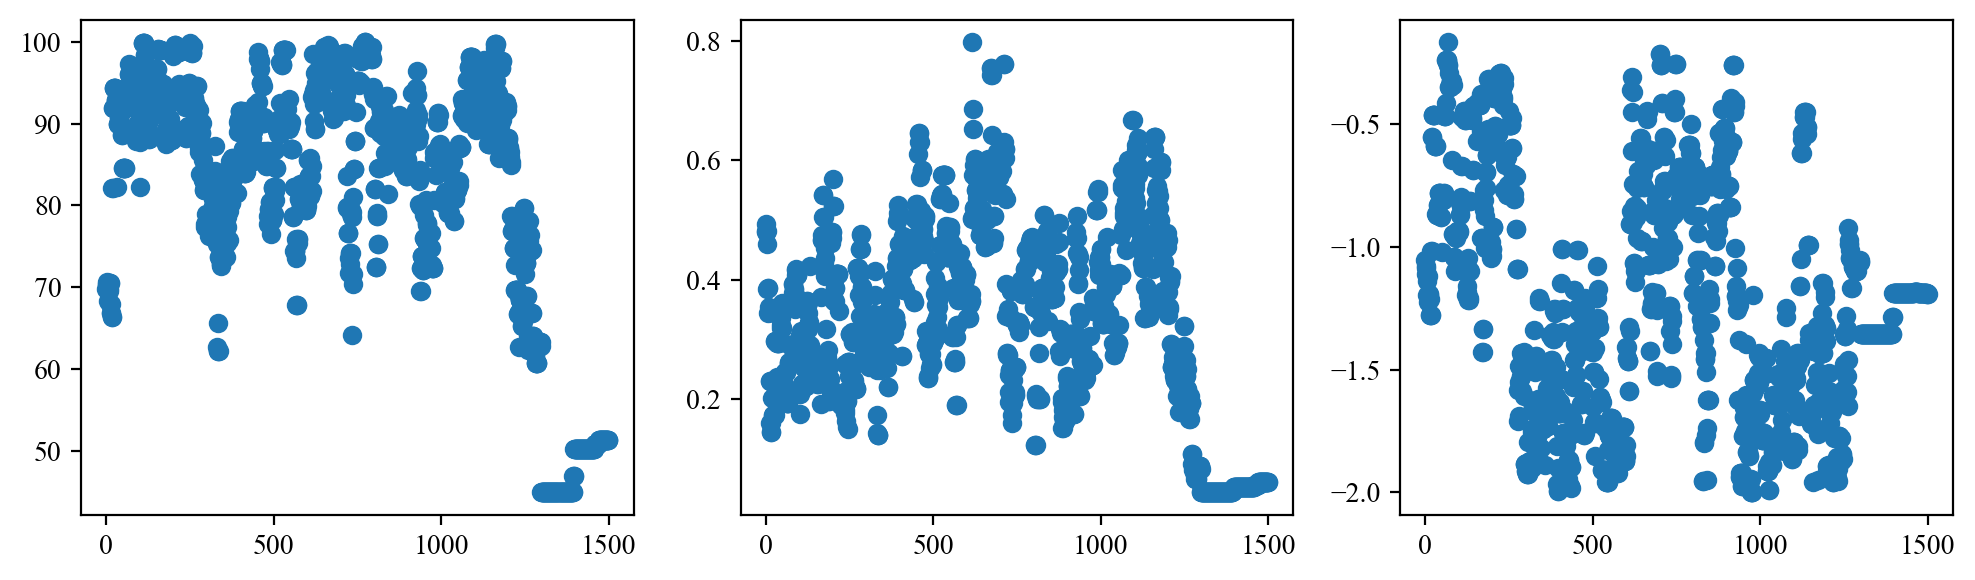

In [68]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3), dpi=200)

for i in range(3):
    axs[i].scatter(np.arange(0, len(samples_PD_gauss)), samples_PD_gauss[:, 0, i])

plt.tight_layout() # Prevents overlap
plt.show()

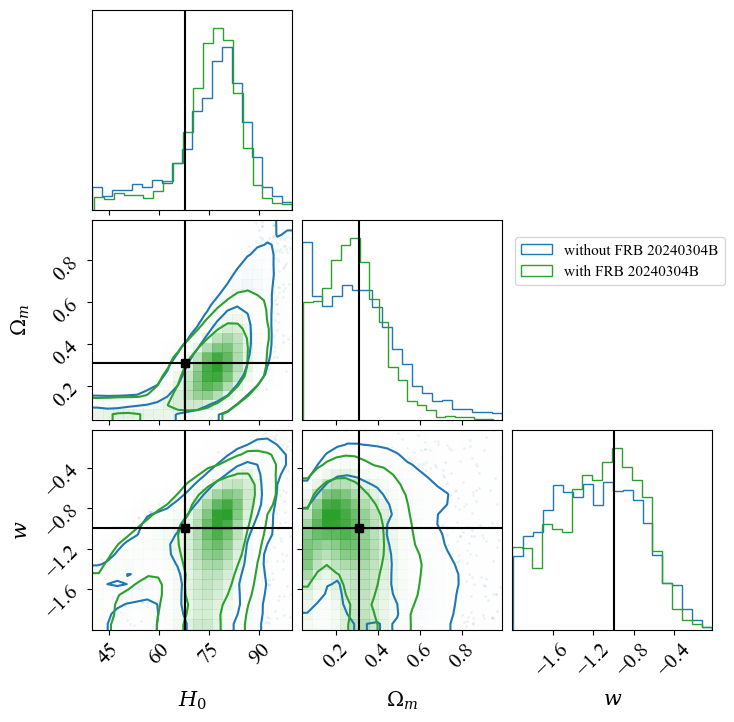

In [69]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$"]

fig = corner.corner(
    flat_samples_PD_pdf_lowZ, labels=labels, color="tab:blue",\
    smooth=True, label_kwargs={"fontsize": 15}, levels=(0.68, 0.95)
)
corner.corner(
    flat_samples_PD_pdf, fig=fig,\
    levels=(0.68, 0.95), color="tab:green", smooth=True,\
    truths=[HUBBLE, OMEGA_MATTER, W_LAMBDA], truth_color='black'
);

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=15)

plt.legend(['without FRB 20240304B', 'with FRB 20240304B'], loc='upper right', bbox_to_anchor=(0.1, 1., 1, 1), fontsize=11)
plt.show()

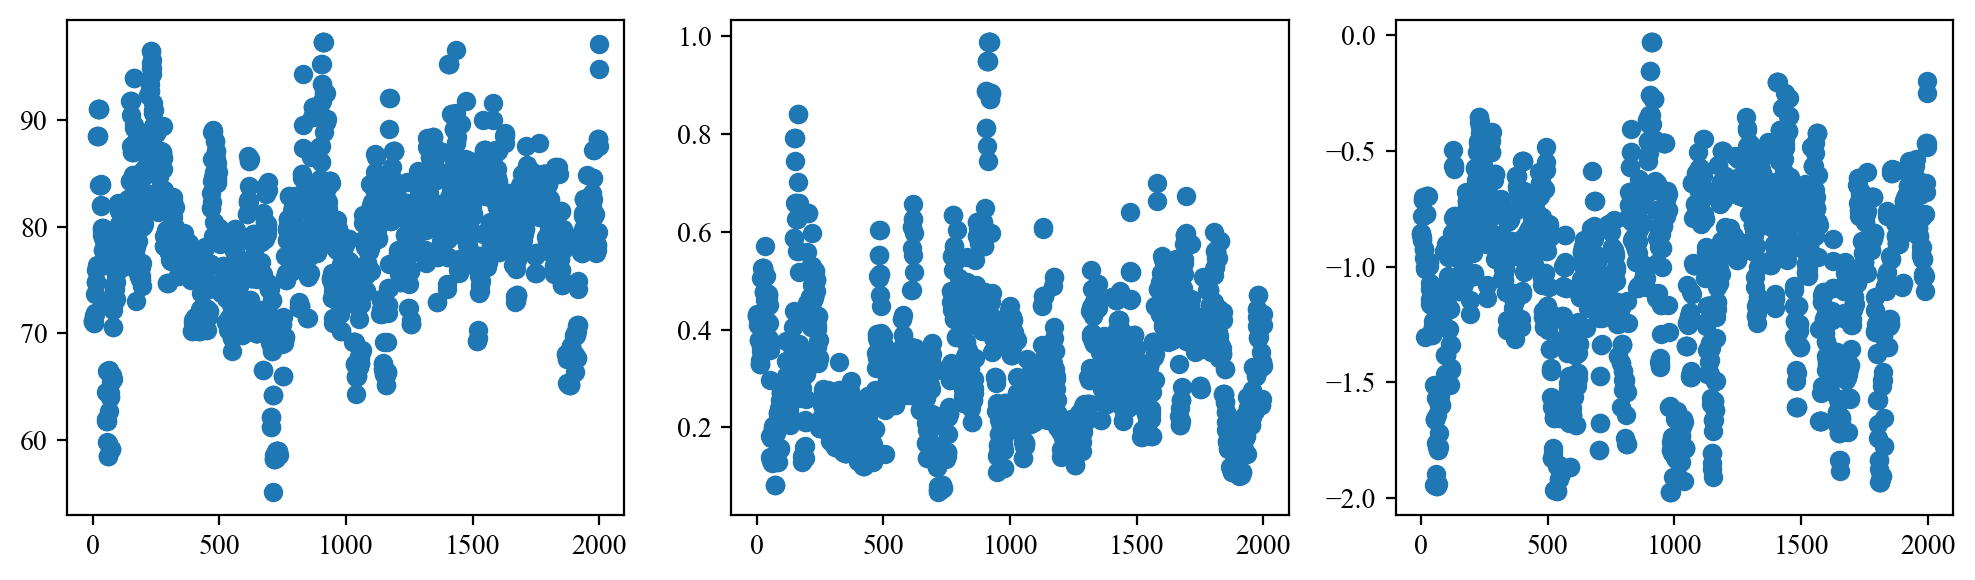

In [70]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3), dpi=200)

for i in range(3):
    axs[i].scatter(np.arange(0, len(samples_PD_pdf)), samples_PD_pdf[:, 0, i])

plt.tight_layout() # Prevents overlap
plt.show()

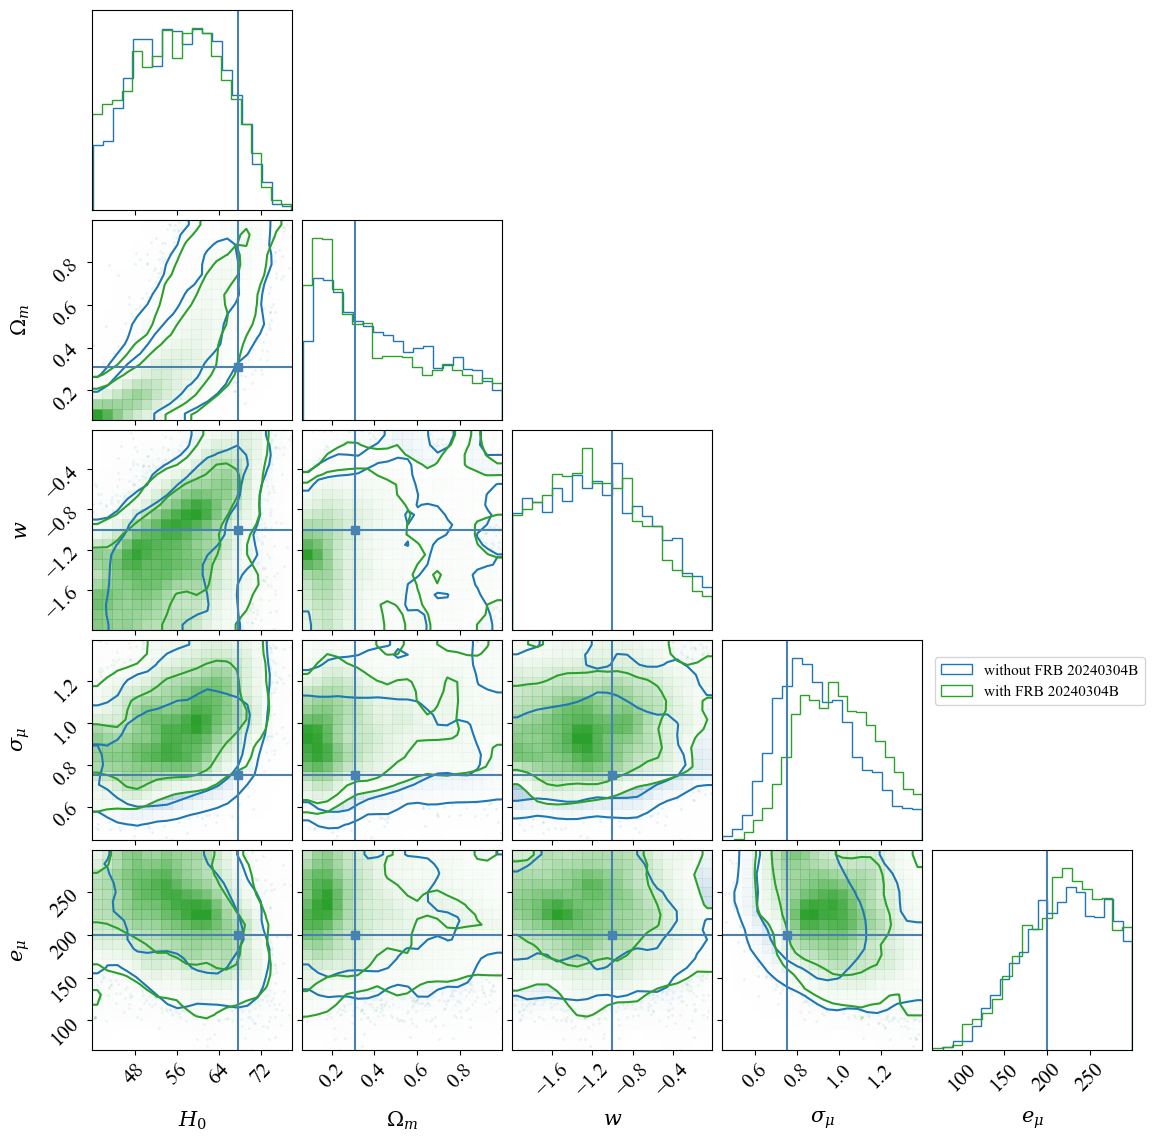

In [15]:
labels = [r"$H_0$", r"$\Omega_m$", r"$w$", r"$\sigma_\mu$", r"$e_\mu$"]

fig = corner.corner(
    flat_samples_PD_pdf_host_lowZ, labels=labels, color="tab:blue",\
    smooth=True, label_kwargs={"fontsize": 15}, levels=(0.68, 0.95)
)
fig = corner.corner(
    flat_samples_PD_pdf_host, fig=fig,\
    levels=(0.68, 0.95), color="tab:green", smooth=True, truths=[HUBBLE, OMEGA_MATTER, W_LAMBDA, 0.75, 200]
);

for ax in fig.get_axes():
    ax.tick_params(axis='both', labelsize=15)

plt.legend(['without FRB 20240304B', 'with FRB 20240304B'], loc='upper right', bbox_to_anchor=(0.1, 1., 1, 1), fontsize=11)
plt.show()

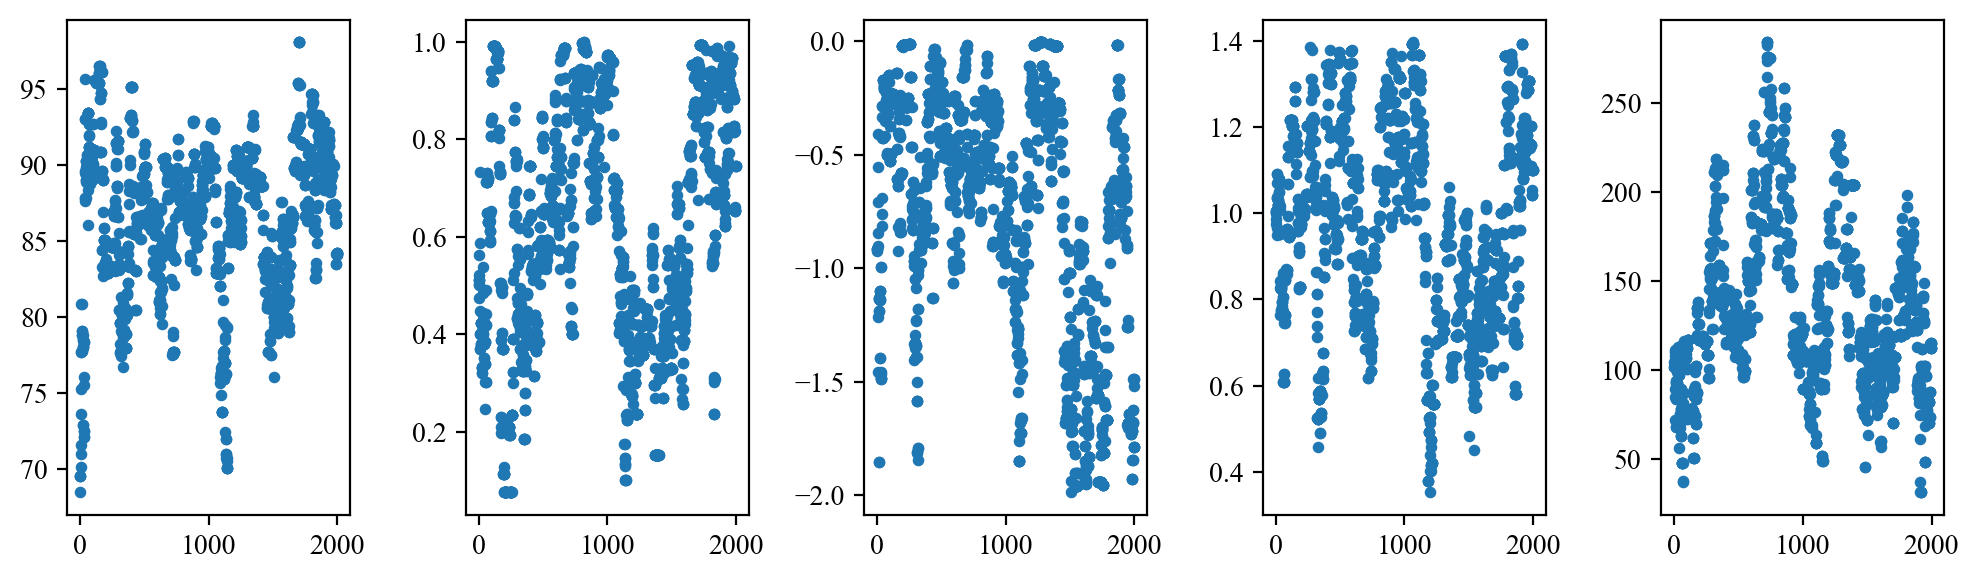

In [13]:
fig, axs = plt.subplots(1, 5, figsize=(10, 3), dpi=200)

for i in range(5):
    axs[i].scatter(np.arange(0, len(samples_PD_pdf_host)), samples_PD_pdf_host[:, 0, i], s=10)

plt.tight_layout() # Prevents overlap
plt.show()